# 04 · Comparación de configuraciones del pipeline

**Preguntas:** ¿qué decisiones del pipeline cambian el desempeño dentro del sujeto y entre sujetos? En particular, **H2**: ¿CSP generaliza mejor que la potencia por banda?

Cada configuración cambia **un solo factor** respecto de la base del notebook 02 (CSP + LDA, 8–30 Hz, ventana 0,5–2,5 s, referencia promedio):

| Factor | Niveles |
|---|---|
| Modelo | potencia por banda (mu y beta, 21 canales motores) + LDA · CSP + LDA · CSP + SVM (RBF) · CSP + Random Forest |
| Banda | mu 8–12 Hz · beta 13–30 Hz · 8–30 Hz |
| Ventana | 0–2 s · 0,5–2,5 s · 1–3 s · 0,5–3,5 s |
| Adaptación | sin alinear · alineación euclídea por sujeto (He y Wu, 2020) |

Los resultados se calculan con `experimentos/etapa4.py` (unas 3 horas) y quedan por sujeto en `resultados/etapa4/`. Este notebook solo los analiza.

**ITR:** se calcula por sujeto con la fórmula de Wolpaw a partir de la balanced accuracy, tomando como tiempo por decisión el final de la ventana (desde la consigna hasta que hay datos para decidir). Por eso una ventana más corta o más temprana puede tener mayor ITR aunque su precisión sea menor.

**La alineación euclídea** blanquea los ensayos de cada sujeto con su covarianza media, sin usar etiquetas. Acá se calcula con todos los ensayos del sujeto (incluidos los de prueba), lo que en un uso real equivale a tener unos minutos de EEG sin etiquetar del usuario nuevo.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon

from bci.pipelines import itr_bits_por_minuto, umbral_azar

RESULTADOS = Path("..") / "resultados"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

df = pd.read_csv(RESULTADOS / "04_resultados.csv")
df["itr"] = itr_bits_por_minuto(df["balanced_accuracy"], df["ventana_fin"])
df["sobre_azar"] = df["balanced_accuracy"] >= df["n_ensayos"].map(umbral_azar)
ORDEN = ["base", "potencia_lda", "csp_svm", "csp_rf", "banda_mu", "banda_beta",
         "ventana_0.0-2.0", "ventana_1.0-3.0", "ventana_0.5-3.5", "alineacion_ea"]
ETIQUETA = {"base": "Base: CSP+LDA, 8–30 Hz, 0,5–2,5 s", "potencia_lda": "Potencia por banda + LDA",
            "csp_svm": "CSP + SVM", "csp_rf": "CSP + Random Forest", "banda_mu": "Banda mu 8–12 Hz",
            "banda_beta": "Banda beta 13–30 Hz", "ventana_0.0-2.0": "Ventana 0–2 s",
            "ventana_1.0-3.0": "Ventana 1–3 s", "ventana_0.5-3.5": "Ventana 0,5–3,5 s",
            "alineacion_ea": "Alineación euclídea"}
print(df.groupby(["config", "esquema"]).size().unstack())


esquema          dentro  entre
config                        
alineacion_ea       106    106
banda_beta          106    106
banda_mu            106    106
base                106    106
csp_rf              106    106
csp_svm             106    106
potencia_lda        106    106
ventana_0.0-2.0     106    106
ventana_0.5-3.5     106    106
ventana_1.0-3.0     106    106


## Tabla resumen

Medias sobre los 106 sujetos. *Pérdida* = balanced accuracy dentro − entre (negativa: el modelo entre sujetos rinde mejor).

In [2]:
ancho = df.pivot_table(index=["config", "sujeto"], columns="esquema",
                       values=["balanced_accuracy", "auc", "itr", "sobre_azar"])
ancho.columns = [f"{m}_{e}" for m, e in ancho.columns]
ancho = ancho.reset_index()
ancho["perdida"] = ancho["balanced_accuracy_dentro"] - ancho["balanced_accuracy_entre"]

tabla = ancho.groupby("config").agg(
    BA_dentro=("balanced_accuracy_dentro", "mean"), BA_entre=("balanced_accuracy_entre", "mean"),
    AUC_dentro=("auc_dentro", "mean"), AUC_entre=("auc_entre", "mean"),
    perdida=("perdida", "mean"),
    ITR_dentro=("itr_dentro", "mean"), ITR_entre=("itr_entre", "mean"),
    sobre_azar_dentro=("sobre_azar_dentro", "sum"), sobre_azar_entre=("sobre_azar_entre", "sum"),
).loc[ORDEN]
tabla.index = [ETIQUETA[c] for c in tabla.index]
tabla.to_csv(RESULTADOS / "04_tabla_resumen.csv")
tabla.round(3)


,BA_dentro,BA_entre,AUC_dentro,AUC_entre,perdida,ITR_dentro,ITR_entre,sobre_azar_dentro,sobre_azar_entre
"Base: CSP+LDA, 8–30 Hz, 0,5–2,5 s",0.604,0.624,0.633,0.709,-0.019,2.353,2.480,32.0,37.0
Potencia por banda + LDA,0.595,0.612,0.627,0.660,-0.017,1.823,1.851,27.0,36.0
CSP + SVM,0.603,0.620,0.635,0.702,-0.017,2.324,2.272,30.0,40.0
CSP + Random Forest,0.583,0.599,0.608,0.662,-0.017,1.768,1.708,27.0,29.0
Banda mu 8–12 Hz,0.596,0.618,0.630,0.683,-0.022,1.981,2.313,31.0,40.0
Banda beta 13–30 Hz,0.595,0.613,0.623,0.691,-0.018,1.988,2.010,29.0,33.0
Ventana 0–2 s,0.611,0.620,0.648,0.714,-0.009,2.620,2.548,38.0,36.0
Ventana 1–3 s,0.576,0.595,0.600,0.668,-0.019,1.552,1.470,29.0,32.0
"Ventana 0,5–3,5 s",0.614,0.612,0.643,0.693,0.002,1.910,1.605,35.0,36.0
Alineación euclídea,0.601,0.691,0.631,0.747,-0.090,2.239,4.340,33.0,64.0


## Pruebas estadísticas

Para cada factor, prueba de Friedman entre todos sus niveles (incluida la base) y luego cada nivel contra la base con Wilcoxon pareado, corrigiendo por comparaciones múltiples con Holm. Todas las pruebas son pareadas por sujeto.

In [3]:
def holm(p):
    p = np.asarray(p); orden = np.argsort(p); m = len(p)
    ajust = np.empty(m); acum = 0
    for rango, i in enumerate(orden):
        acum = max(acum, (m - rango) * p[i]); ajust[i] = min(1, acum)
    return ajust

FACTORES = {"modelo": ["base", "potencia_lda", "csp_svm", "csp_rf"],
            "banda": ["base", "banda_mu", "banda_beta"],
            "ventana": ["base", "ventana_0.0-2.0", "ventana_1.0-3.0", "ventana_0.5-3.5"],
            "adaptacion": ["base", "alineacion_ea"]}
filas = []
for esquema in ["dentro", "entre"]:
    for metrica in ["balanced_accuracy", "auc"]:
        col = f"{metrica}_{esquema}"
        mat = ancho.pivot(index="sujeto", columns="config", values=col)
        for factor, niveles in FACTORES.items():
            p_fr = friedmanchisquare(*[mat[n] for n in niveles]).pvalue if len(niveles) > 2 else np.nan
            ps = [wilcoxon(mat[n], mat["base"]).pvalue for n in niveles[1:]]
            for n, p, pa in zip(niveles[1:], ps, holm(ps)):
                filas.append({"esquema": esquema, "métrica": metrica, "factor": factor,
                              "nivel": ETIQUETA[n], "diferencia vs base": (mat[n] - mat["base"]).mean(),
                              "p Friedman (factor)": p_fr, "p Wilcoxon": p, "p Holm": pa})
pruebas = pd.DataFrame(filas)
pruebas.to_csv(RESULTADOS / "04_pruebas.csv", index=False)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pruebas[pruebas["métrica"] == "balanced_accuracy"])


,esquema,métrica,factor,nivel,diferencia vs base,p Friedman (factor),p Wilcoxon,p Holm
0,dentro,balanced_accuracy,modelo,Potencia por banda + LDA,-0.00958,0.00043,0.543,1
1,dentro,balanced_accuracy,modelo,CSP + SVM,-0.00155,0.00043,0.539,1
2,dentro,balanced_accuracy,modelo,CSP + Random Forest,-0.0219,0.00043,4.59e-06,1.38e-05
3,dentro,balanced_accuracy,banda,Banda mu 8–12 Hz,-0.00847,0.854,0.497,0.901
4,dentro,balanced_accuracy,banda,Banda beta 13–30 Hz,-0.00963,0.854,0.451,0.901
5,dentro,balanced_accuracy,ventana,Ventana 0–2 s,0.00608,2.74e-05,0.836,0.836
6,dentro,balanced_accuracy,ventana,Ventana 1–3 s,-0.0279,2.74e-05,1.47e-05,4.4e-05
7,dentro,balanced_accuracy,ventana,"Ventana 0,5–3,5 s",0.00958,2.74e-05,0.17,0.341
8,dentro,balanced_accuracy,adaptacion,Alineación euclídea,-0.0033,NaN,0.0239,0.0239
18,entre,balanced_accuracy,modelo,Potencia por banda + LDA,-0.0116,0.00155,0.6,1


### H2: ¿CSP generaliza mejor que la potencia por banda?

Se compara CSP + LDA (base) contra potencia por banda + LDA en los dos esquemas, y también la **pérdida** de cada uno (cuánto cae al pasar a entre sujetos).

In [4]:
m = {c: ancho[ancho.config == c].set_index("sujeto") for c in ["base", "potencia_lda"]}
for col, nombre in [("balanced_accuracy_dentro", "BA dentro"), ("balanced_accuracy_entre", "BA entre"),
                    ("auc_entre", "AUC entre"), ("perdida", "pérdida")]:
    a, b = m["base"][col], m["potencia_lda"][col]
    print(f"{nombre:10s} CSP {a.mean():.3f} | potencia {b.mean():.3f} | dif {a.mean() - b.mean():+.3f} | "
          f"Wilcoxon p = {wilcoxon(a, b).pvalue:.2g}")


BA dentro  CSP 0.604 | potencia 0.595 | dif +0.010 | Wilcoxon p = 0.54
BA entre   CSP 0.624 | potencia 0.612 | dif +0.012 | Wilcoxon p = 0.6
AUC entre  CSP 0.709 | potencia 0.660 | dif +0.049 | Wilcoxon p = 3.4e-08
pérdida    CSP -0.019 | potencia -0.017 | dif -0.002 | Wilcoxon p = 0.93


## Figura 1 · Balanced accuracy por configuración

Media sobre los 106 sujetos con su IC 95 %. La figura la genera `experimentos/figura_etapa4.py` (es la misma que va en el informe). Los intervalos se superponen porque la variabilidad entre sujetos es grande; las comparaciones que importan son las pareadas por sujeto de la tabla anterior.

listo: F:\Users\Lucas\Scripts\tfi-bci-imagineria-motora\resultados\04_configuraciones.png


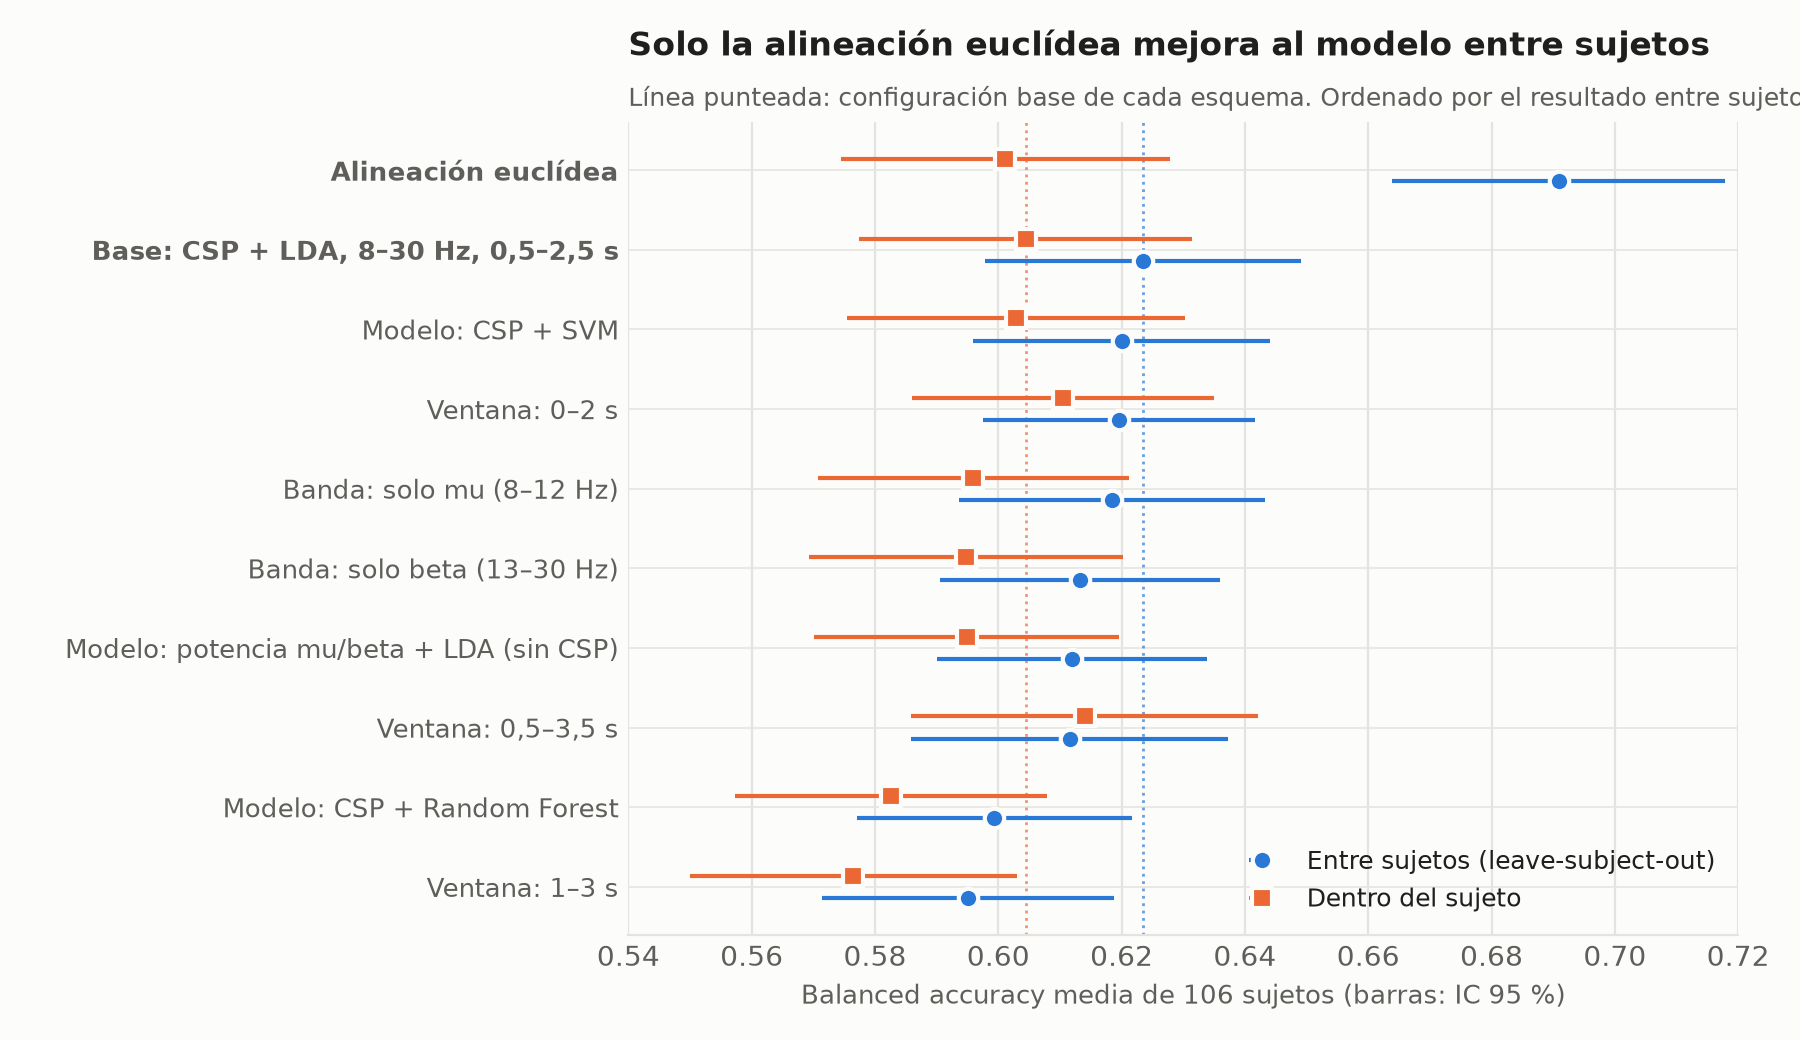

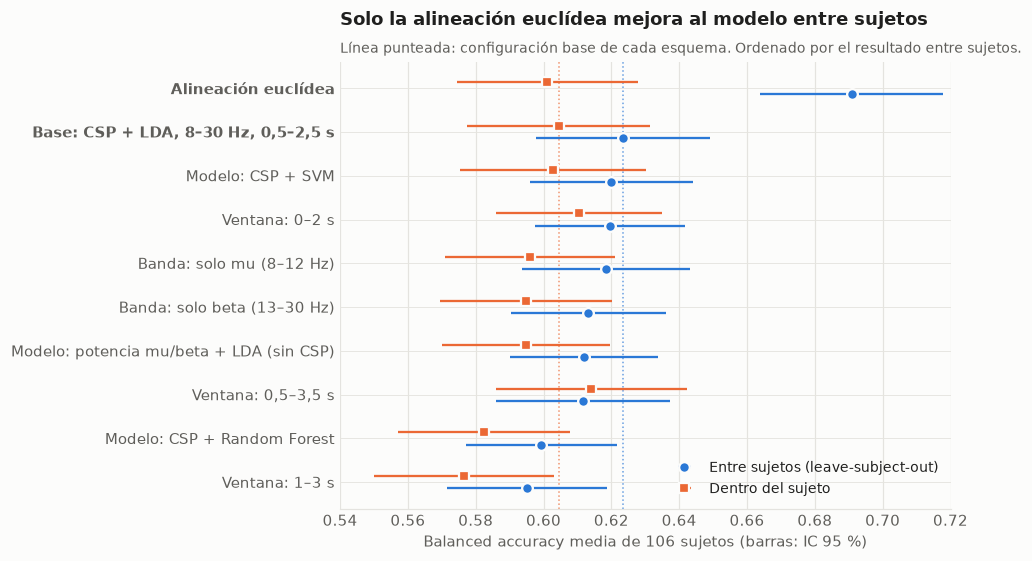

In [5]:
from IPython.display import Image
from experimentos.figura_etapa4 import main as figura_configuraciones

figura_configuraciones()
Image(RESULTADOS / "04_configuraciones.png", width=800)


## Figura 2 · Ventana temporal: precisión contra velocidad

Para la BCI no alcanza con acertar: también importa cuánto tarda en decidir. El ITR combina las dos cosas.

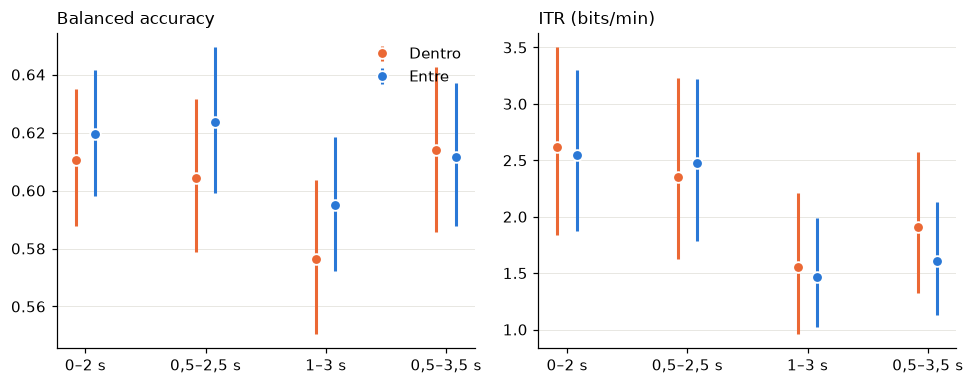

In [6]:
rng = np.random.default_rng(0)
def ic95(v, n=2000):
    v = np.asarray(v); medias = rng.choice(v, (n, len(v))).mean(1)
    return np.percentile(medias, [2.5, 97.5])

vent = ["ventana_0.0-2.0", "base", "ventana_1.0-3.0", "ventana_0.5-3.5"]
nombres = ["0–2 s", "0,5–2,5 s", "1–3 s", "0,5–3,5 s"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, metrica, titulo in [(axes[0], "balanced_accuracy", "Balanced accuracy"), (axes[1], "itr", "ITR (bits/min)")]:
    for esquema, color, desplaz, et in [("dentro", NARANJA, -0.08, "Dentro"), ("entre", AZUL, 0.08, "Entre")]:
        col = f"{metrica}_{esquema}"
        medias = [ancho.loc[ancho.config == c, col].mean() for c in vent]
        ics = np.array([ic95(ancho.loc[ancho.config == c, col]) for c in vent])
        x = np.arange(len(vent)) + desplaz
        ax.errorbar(x, medias, yerr=[np.array(medias) - ics[:, 0], ics[:, 1] - np.array(medias)],
                    fmt="o", color=color, ms=7, mec="white", mew=1.2, capsize=0, lw=2, label=et)
    ax.set_xticks(range(len(vent)), nombres)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTADOS / "04_ventanas.png", dpi=200)


## Lectura de los resultados

**1. Solo la alineación euclídea cambia el resultado.** Entre sujetos, la balanced accuracy pasa de 0,624 a 0,691 (+0,067, p Holm < 0,001), el AUC de 0,709 a 0,747 y los sujetos por encima del azar de 37 a 64 de 106. Dentro del sujeto no mejora (0,601 contra 0,604): la alineación acerca personas distintas, y dentro de una misma persona no hay nada que acercar. Con alineación, el modelo entre sujetos supera al personal en 9 puntos.

**2. La mayoría de las decisiones del pipeline importan poco.** SVM en lugar de LDA, solo mu, solo beta, la ventana 0–2 s o la 0,5–3,5 s: ninguna cambia la balanced accuracy de forma significativa. Dos empeoran en los dos esquemas: **Random Forest** (−0,024 entre sujetos), que con solo 6 características no tiene qué aprovechar y sobreajusta, y la **ventana 1–3 s** (−0,028), que pierde el tramo 0,5–1,5 s, donde el notebook 01 mostró la mayor diferencia entre manos.

**3. H2 se sostiene solo en parte.** CSP no supera a la potencia por banda en balanced accuracy (0,624 contra 0,612, p = 0,60), pero sí en AUC entre sujetos (0,709 contra 0,660, p < 0,001): ordena mejor los ensayos, pero el umbral mal ubicado (notebook 02) se come la ventaja. Algo parecido pasa con las bandas: mu sola o beta sola no cambian la balanced accuracy, pero bajan el AUC entre sujetos, así que las dos aportan información.

**4. ITR.** Con el tiempo por decisión igual al final de la ventana, la base da 2,5 bits/min entre sujetos y la alineación 4,3. La ventana 0–2 s tiene un ITR algo mayor que la base (2,55 contra 2,48 bits/min entre sujetos; 2,62 contra 2,35 dentro) porque decide medio segundo antes con casi la misma precisión.

**Limitación.** Acá el sujeto evaluado se alinea con todos sus ensayos (sin etiquetas), un supuesto optimista. El notebook 05 evalúa la versión realista, alineando solo con unos pocos ensayos de calibración.
